In [168]:
#THIS NOTEBOOK GENERATES RESULT PLOTS FOR THE OFFICIAL DHFUS BASELINE MODEL

import pandas as pd                                     #IMPORTS DATAFRAME HANDLING LIBRARY
import numpy as np                                      #IMPORTS NUMERICAL OPERATIONS LIBRARY
import matplotlib.pyplot as plt                         #IMPORTS LIBRARY FOR MATLAB STYLE PLOTTING

from rdkit import Chem                                  #IMPORTS CHEMICAL STRUCTURE HANDLING LIBRARY FOR MOLECULAR CLASSIFICATION IN PLOTS 

import pandas as pd
from pathlib import Path                                #IMPORTS FILE PATH HANDLING LIBRARY

print("Working directory:", Path.cwd())                                         #VERIFIES WORKING DIRECTORY AS THE SAME ONE USED BY BASELINE
df_check = pd.read_csv("dHfus_baseline_predictions.csv")
print("Columns:", df_check.columns.tolist())
print("Full path:", (Path.cwd() / "dHfus_baseline_predictions.csv").resolve())


import pandas as pd                                                             #VERIFIES THAT FUNCTION CHANGES PROPOGATED THROUGH
df = pd.read_csv("dHfus_baseline_predictions.csv")
print(df.columns.tolist())





Working directory: c:\Users\Jaco Olivier\Downloads\SCRIPSIE\Code Related\Implement
Columns: ['run_name', 'smiles', 'y_true', 'y_pred', 'abs_error', 'rel_error_pct']
Full path: C:\Users\Jaco Olivier\Downloads\SCRIPSIE\Code Related\Implement\dHfus_baseline_predictions.csv
['run_name', 'smiles', 'y_true', 'y_pred', 'abs_error', 'rel_error_pct']


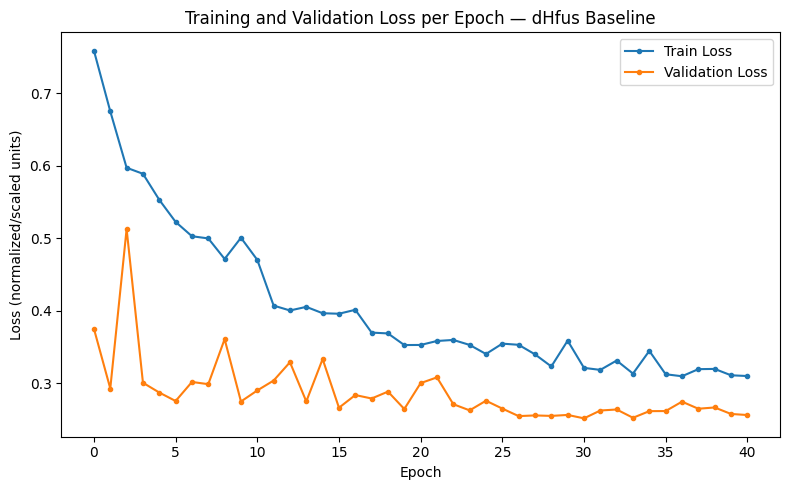

Split      MAE     RMSE    N
Train 1.899973 3.759483 3727
 Test 1.464109 2.014384  465


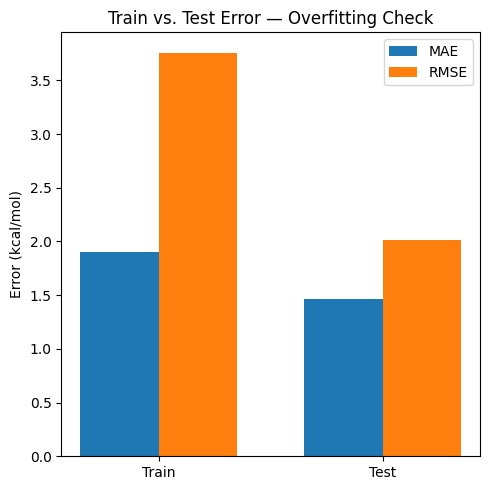


Test MAE is -22.9% lower than train MAE
Train — mean: 1.8999731010104783 median: 1.2560325149121088
Test — mean: 1.464109116744751 median: 1.0825510594360352


In [169]:
#LOSS CURVE
metrics_df = pd.read_csv("dHfus_baseline_loss_curve.csv")
epoch_metrics = metrics_df.groupby("epoch")[["train_loss_epoch", "val_loss"]].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epoch_metrics.index, epoch_metrics["train_loss_epoch"], label="Train Loss", marker="o", markersize=3)
ax.plot(epoch_metrics.index, epoch_metrics["val_loss"], label="Validation Loss", marker="o", markersize=3)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (normalized/scaled units)")
ax.set_title("Training and Validation Loss per Epoch — dHfus Baseline")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_loss_curves.png", dpi=150)
plt.show()


#TRAIN VS TEST ERROR
train_predictions = pd.read_csv("dHfus_baseline_train_predictions.csv")

train_mae = train_predictions["abs_error"].mean()
test_mae = predictions["abs_error"].mean()
train_rmse = np.sqrt((train_predictions["abs_error"] ** 2).mean())
test_rmse = np.sqrt((predictions["abs_error"] ** 2).mean())

comparison = pd.DataFrame({
    "Split": ["Train", "Test"], "MAE": [train_mae, test_mae], "RMSE": [train_rmse, test_rmse],
    "N": [len(train_predictions), len(predictions)],
})
print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, comparison["MAE"], width, label="MAE")
ax.bar(x + width/2, comparison["RMSE"], width, label="RMSE")
ax.set_xticks(x)
ax.set_xticklabels(["Train", "Test"])
ax.set_ylabel("Error (kcal/mol)")
ax.set_title("Train vs. Test Error — Overfitting Check")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_train_vs_test.png", dpi=150)
plt.show()

gap_pct = (test_mae - train_mae) / train_mae * 100
print(f"\nTest MAE is {gap_pct:.1f}% {'higher' if gap_pct > 0 else 'lower'} than train MAE")

print("Train — mean:", train_predictions["abs_error"].mean(), "median:", train_predictions["abs_error"].median())
print("Test — mean:", predictions["abs_error"].mean(), "median:", predictions["abs_error"].median())


In [170]:
predictions = pd.read_csv("dHfus_baseline_predictions.csv")    #READS SAVED PREDICTIONS FROM BASELINE CSV
print(predictions.shape)
predictions.head()

FUNCTIONAL_GROUPS = {                                          #RUDIMENTARY FUNCTIONAL GROUP DEFINITIONS TO BE USED IN PLOTS
    "Carboxylic acid": "[CX3](=O)[OX2H1]",
    "Ester": "[#6][CX3](=O)[OX2H0][#6]",
    "Amide": "[CX3](=[OX1])[NX3]",
    "Amine": "[NX3;H2,H1,H0;!$(NC=O)]",
    "Alcohol": "[OX2H][CX4]",
    "Ether": "[OD2]([#6])[#6]",
    "Aromatic": "c1ccccc1",
    "Alkene": "[CX3]=[CX3]",
    "Alkyne": "[CX2]#[CX2]",        
}


def classify_molecule(smi):                                     #CLASSIFIES MOLECULES BASED ON FUNCTIONAL GROUPS USING RDKit
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return "Unknown"
    for name, smarts in FUNCTIONAL_GROUPS.items():
        pattern = Chem.MolFromSmarts(smarts)
        if mol.HasSubstructMatch(pattern):
            return name
    return "Alkane/Other"

predictions["functional_class"] = predictions["smiles"].apply(classify_molecule)     
print(predictions["functional_class"].value_counts())



(465, 6)
functional_class
Aromatic           178
Ester               87
Amine               49
Alkane/Other        45
Carboxylic acid     34
Ether               32
Amide               19
Alcohol             18
Alkene               3
Name: count, dtype: int64


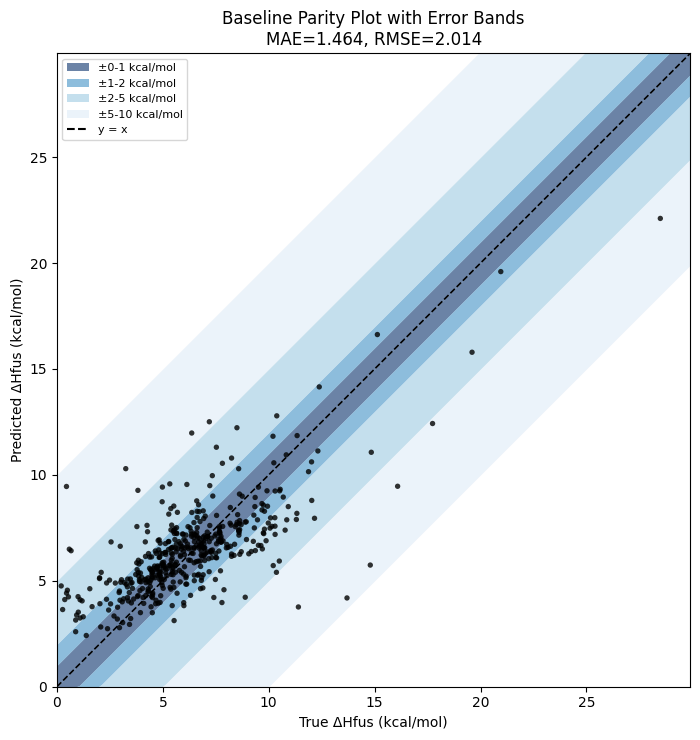

                  count      mean    median
functional_class                           
Alkene                3  2.287753  2.410683
Ether                32  2.278420  1.624925
Alcohol              18  2.104929  1.569909
Alkane/Other         45  1.920848  1.283809
Amine                49  1.546759  1.267228
Ester                87  1.349100  1.047566
Amide                19  1.303477  1.202760
Carboxylic acid      34  1.273009  0.825996
Aromatic            178  1.210674  0.938464
Band (kcal/mol)  Count  Percentage  Cumulative %
            0-1    215        46.2          46.2
            1-2    140        30.1          76.3
            2-5     97        20.9          97.2
           5-10     13         2.8         100.0
            >10      0         0.0         100.0


In [171]:
#BASELINE PARITY PLOT: MOST INTUITIVE REPRESENTATION OF ERROR
fig, ax = plt.subplots(figsize=(7.5, 7.5))

max_val = max(predictions["y_true"].max(), predictions["y_pred"].max()) * 1.05
x_line = np.linspace(0, max_val, 200)

#SHADED ERROR BANDS, DARKEST CLOSEST TO y=x, FADING OUTWARD
bands = [(0, 1, "#08306b"), (1, 2, "#4292c6"), (2, 5, "#9ecae1"), (5, 10, "#deebf7")]
for lo, hi, color in bands:
    ax.fill_between(x_line, x_line + lo, x_line + hi, color=color, alpha=0.6, linewidth=0)
    ax.fill_between(x_line, np.maximum(x_line - hi, 0), np.maximum(x_line - lo, 0), color=color, alpha=0.6, linewidth=0)

ax.plot(x_line, x_line, "k--", linewidth=1.2, label="y = x", zorder=5)
ax.scatter(predictions["y_true"], predictions["y_pred"], color="black", s=15, alpha=0.8, zorder=6, edgecolor="none")

mae = predictions["abs_error"].mean()
rmse = np.sqrt((predictions["abs_error"] ** 2).mean())

#MANUAL LEGEND FOR THE SHADED BANDS
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, alpha=0.6, label=f"±{lo}-{hi} kcal/mol") for lo, hi, c in bands]
legend_elements.append(plt.Line2D([0], [0], color="black", linestyle="--", label="y = x"))
ax.legend(handles=legend_elements, loc="upper left", fontsize=8)

ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.set_xlabel("True ΔHfus (kcal/mol)")
ax.set_ylabel("Predicted ΔHfus (kcal/mol)")
ax.set_title(f"Baseline Parity Plot with Error Bands\nMAE={mae:.3f}, RMSE={rmse:.3f}")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("plots_dHfus_parity_bands.png", dpi=150)
plt.show()

#PER-CLASS ERROR TABLE — SAME INFO AS THE COLORED PLOT, BUT NUMERIC
class_errors = predictions.groupby("functional_class")["abs_error"].agg(["count", "mean", "median"]).sort_values("mean", ascending=False)
print(class_errors)

bins = [0, 1, 2, 5, 10, np.inf]
labels = ["0-1", "1-2", "2-5", "5-10", ">10"]

predictions["error_band"] = pd.cut(predictions["abs_error"], bins=bins, labels=labels, right=True)

band_counts = predictions["error_band"].value_counts().reindex(labels)
band_pct = (band_counts / len(predictions) * 100)
cumulative_pct = band_pct.cumsum()

error_band_table = pd.DataFrame({
    "Band (kcal/mol)": labels,
    "Count": band_counts.values,
    "Percentage": band_pct.round(1).values,
    "Cumulative %": cumulative_pct.round(1).values,
})

print(error_band_table.to_string(index=False))
error_band_table.to_csv("dHfus_baseline_error_bands.csv", index=False)


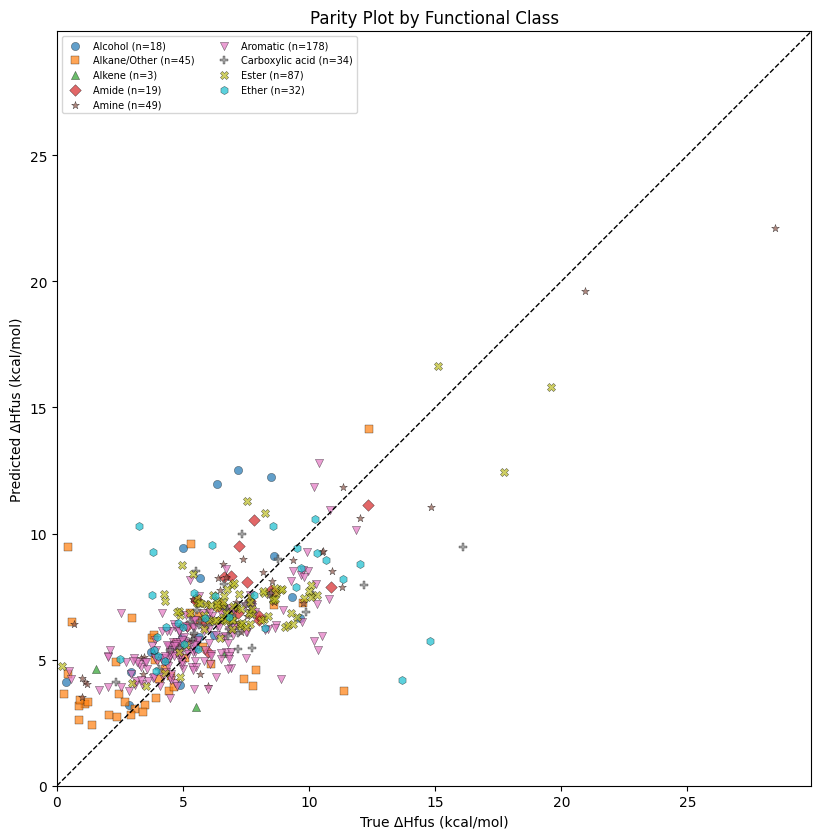

In [172]:
#PER-CLASS PARITY PLOT — SAME INFO AS THE TABLE, BUT VISUAL
fig, ax = plt.subplots(figsize=(8.5, 8.5))
classes = sorted(predictions["functional_class"].unique())
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))
markers = ["o", "s", "^", "D", "*", "v", "P", "X", "h"]  

for cls, color, marker in zip(classes, colors, markers):
    subset = predictions[predictions["functional_class"] == cls]
    ax.scatter(subset["y_true"], subset["y_pred"], alpha=0.7, s=35, color=color, marker=marker,
               label=f"{cls} (n={len(subset)})", edgecolor="black", linewidth=0.3)

max_val = max(predictions["y_true"].max(), predictions["y_pred"].max()) * 1.05
ax.plot([0, max_val], [0, max_val], "k--", linewidth=1)
ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.set_xlabel("True ΔHfus (kcal/mol)")
ax.set_ylabel("Predicted ΔHfus (kcal/mol)")
ax.set_title("Parity Plot by Functional Class")
ax.legend(loc="upper left", fontsize=7, ncol=2)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("plots_dHfus_parity_by_class.png", dpi=150)
plt.show()

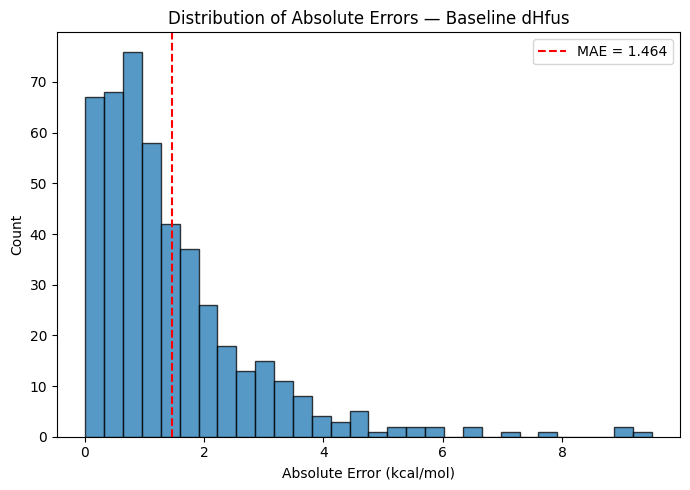

Excluding 6 molecules with |y_true| < 0.5 kcal/mol


In [173]:
#ABSOLUTE ERROR HISTOGRAM: SHOWS DISTRIBUTIONS
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(predictions["abs_error"], bins=30, edgecolor="black", alpha=0.75)
ax.axvline(mae, color="red", linestyle="--", label=f"MAE = {mae:.3f}")
ax.set_xlabel("Absolute Error (kcal/mol)")
ax.set_ylabel("Count")
ax.set_title("Distribution of Absolute Errors — Baseline dHfus")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_abs_error_hist.png", dpi=150)
plt.show()

near_zero_threshold = 0.5  # kcal/mol
near_zero_mask = predictions["y_true"].abs() < near_zero_threshold
n_excluded = near_zero_mask.sum()
print(f"Excluding {n_excluded} molecules with |y_true| < {near_zero_threshold} kcal/mol")


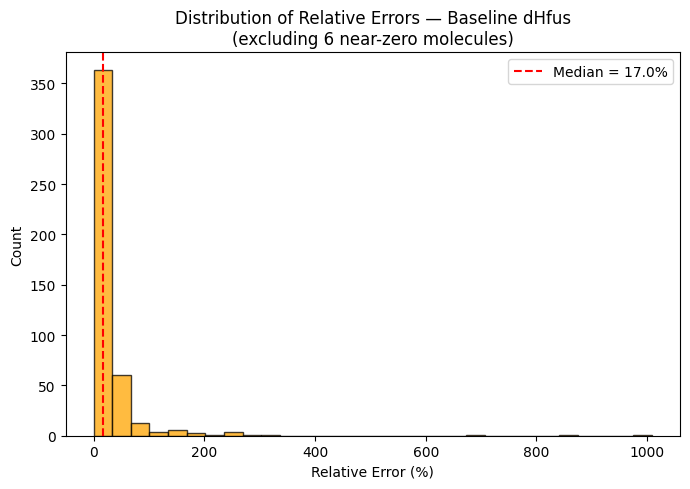

In [174]:

rel_error_filtered = predictions.loc[~near_zero_mask, "rel_error_pct"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(rel_error_filtered, bins=30, edgecolor="black", alpha=0.75, color="orange")
ax.axvline(rel_error_filtered.median(), color="red", linestyle="--",
           label=f"Median = {rel_error_filtered.median():.1f}%")
ax.set_xlabel("Relative Error (%)")
ax.set_ylabel("Count")
ax.set_title(f"Distribution of Relative Errors — Baseline dHfus\n(excluding {n_excluded} near-zero molecules)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_rel_error_hist.png", dpi=150)
plt.show()


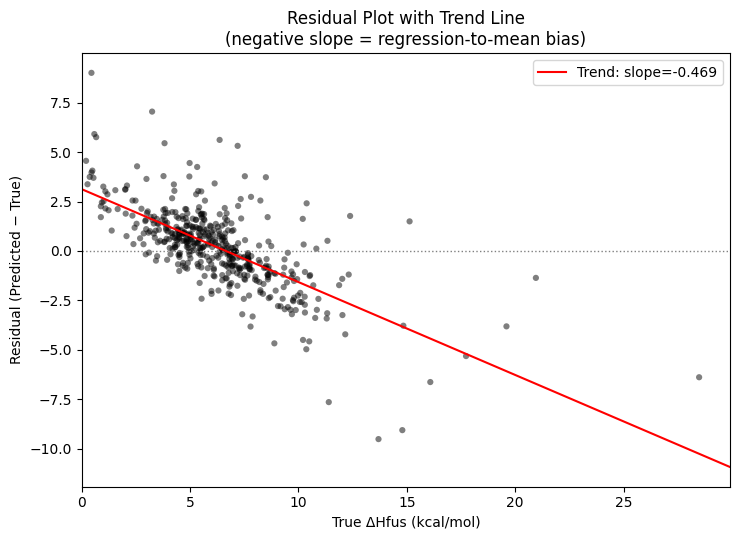

Residual trend slope: -0.4694 (negative = model underpredicts at high values, overpredicts at low values)


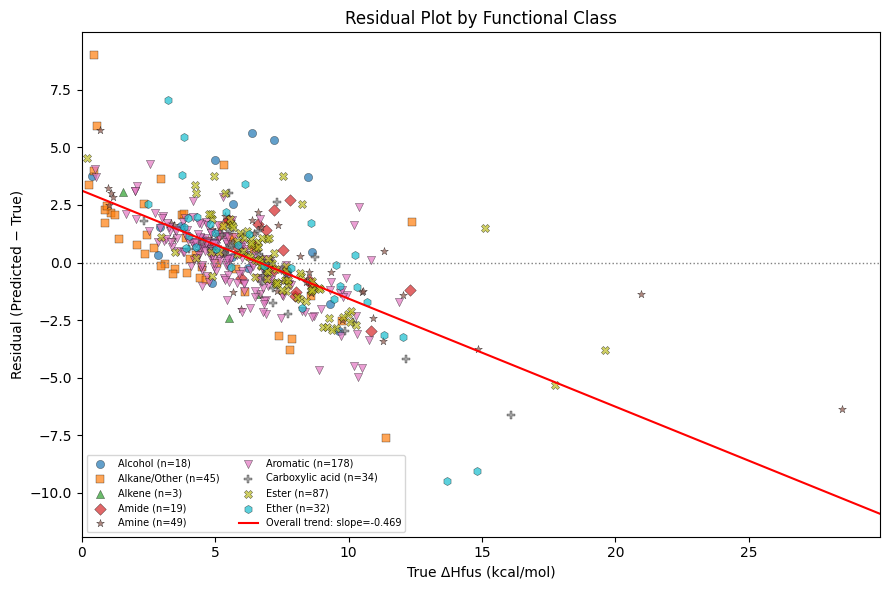

Per-class residual trend (slope) and mean residual:
  Alcohol              n= 18  mean_residual=+1.394  trend_slope=-0.299
  Alkane/Other         n= 45  mean_residual=+0.741  trend_slope=-0.619
  Alkene               n=  3  (too few points for trend)
  Amide                n= 19  mean_residual=+0.262  trend_slope=-0.544
  Amine                n= 49  mean_residual=+0.144  trend_slope=-0.343
  Aromatic             n=178  mean_residual=+0.115  trend_slope=-0.550
  Carboxylic acid      n= 34  mean_residual=-0.267  trend_slope=-0.662
  Ester                n= 87  mean_residual=-0.027  trend_slope=-0.477
  Ether                n= 32  mean_residual=+0.215  trend_slope=-0.852


In [175]:
#RESIDUAL PLOT: SHOWS WHERE PREDICTIONS ARE OVER OR UNDER ESTIMATED
predictions["residual"] = predictions["y_pred"] - predictions["y_true"]

slope, intercept = np.polyfit(predictions["y_true"], predictions["residual"], 1)
trend_x = np.array([0, predictions["y_true"].max() * 1.05])
trend_y = slope * trend_x + intercept

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(predictions["y_true"], predictions["residual"], alpha=0.5, s=20, color="black", edgecolor="none")
ax.axhline(0, color="gray", linestyle=":", linewidth=1)
ax.plot(trend_x, trend_y, color="red", linewidth=1.5, label=f"Trend: slope={slope:.3f}")
ax.set_xlim(0, predictions["y_true"].max() * 1.05)
ax.set_xlabel("True ΔHfus (kcal/mol)")
ax.set_ylabel("Residual (Predicted − True)")
ax.set_title("Residual Plot with Trend Line\n(negative slope = regression-to-mean bias)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_residuals_trend.png", dpi=150)
plt.show()

print(f"Residual trend slope: {slope:.4f} (negative = model underpredicts at high values, overpredicts at low values)")

fig, ax = plt.subplots(figsize=(9, 6))
classes = sorted(predictions["functional_class"].unique())
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))
markers = ["o", "s", "^", "D", "*", "v", "P", "X", "h"]

for cls, color, marker in zip(classes, colors, markers):
    subset = predictions[predictions["functional_class"] == cls]
    ax.scatter(subset["y_true"], subset["residual"], alpha=0.7, s=35, color=color, marker=marker,
               label=f"{cls} (n={len(subset)})", edgecolor="black", linewidth=0.3)

ax.axhline(0, color="gray", linestyle=":", linewidth=1)

slope, intercept = np.polyfit(predictions["y_true"], predictions["residual"], 1)
trend_x = np.array([0, predictions["y_true"].max() * 1.05])
ax.plot(trend_x, slope * trend_x + intercept, color="red", linewidth=1.5, label=f"Overall trend: slope={slope:.3f}")

ax.set_xlim(0, predictions["y_true"].max() * 1.05)
ax.set_xlabel("True ΔHfus (kcal/mol)")
ax.set_ylabel("Residual (Predicted − True)")
ax.set_title("Residual Plot by Functional Class")
ax.legend(loc="lower left", fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("plots_dHfus_residuals_by_class.png", dpi=150)
plt.show()

#PER-CLASS RESIDUAL TREND — CHECKS IF THE OVERALL BIAS IS UNIFORM ACROSS CLASSES OR DRIVEN BY SPECIFIC ONES
print("Per-class residual trend (slope) and mean residual:")
for cls in classes:
    subset = predictions[predictions["functional_class"] == cls]
    if len(subset) >= 5:  # skip classes too small for a meaningful trend line
        cls_slope, _ = np.polyfit(subset["y_true"], subset["residual"], 1)
        print(f"  {cls:20s} n={len(subset):3d}  mean_residual={subset['residual'].mean():+.3f}  trend_slope={cls_slope:+.3f}")
    else:
        print(f"  {cls:20s} n={len(subset):3d}  (too few points for trend)")



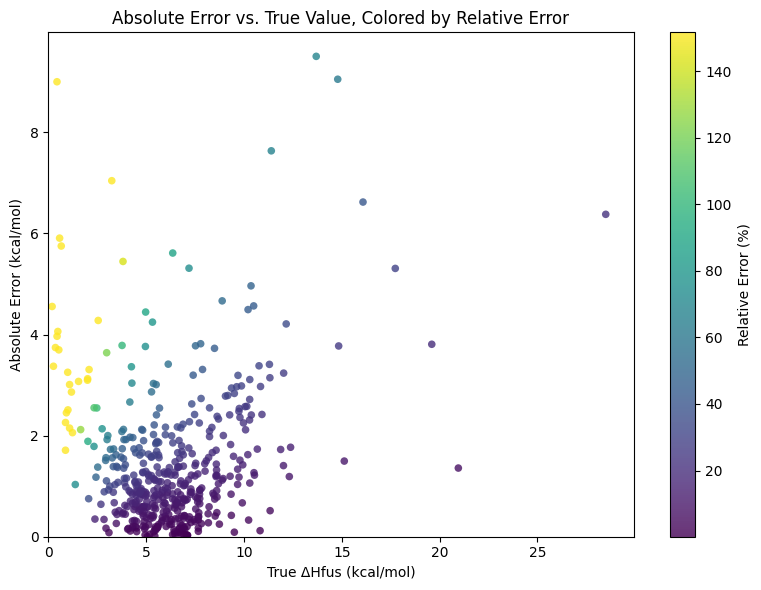

In [176]:
#BUBBLE PLOT: ABSOLUTE ERROR VS TRUE VALUE, COLORED BY RELATIVE ERROR
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(predictions["y_true"], predictions["abs_error"], c=predictions["rel_error_pct"],
                 cmap="viridis", s=30, alpha=0.8, edgecolor="none", vmax=predictions["rel_error_pct"].quantile(0.95))
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Relative Error (%)")
ax.set_xlim(0, predictions["y_true"].max() * 1.05)
ax.set_ylim(0, predictions["abs_error"].max() * 1.05)
ax.set_xlabel("True ΔHfus (kcal/mol)")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Absolute Error vs. True Value, Colored by Relative Error")
plt.tight_layout()
plt.savefig("plots_dHfus_error_bubble.png", dpi=150)
plt.show()


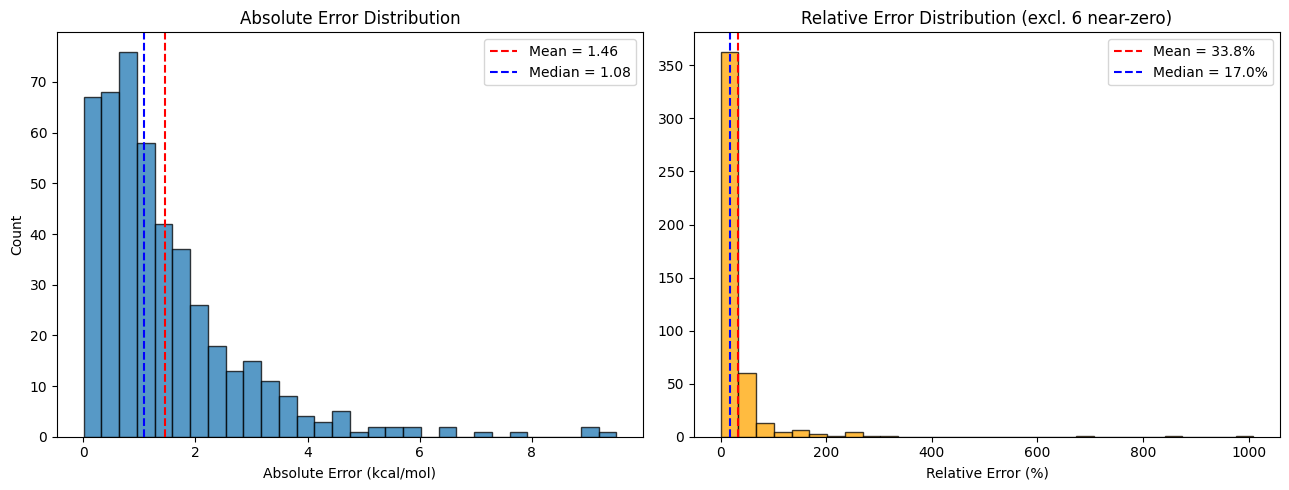

In [177]:
near_zero_threshold = 0.5
near_zero_mask = predictions["y_true"].abs() < near_zero_threshold
rel_error_filtered = predictions.loc[~near_zero_mask, "rel_error_pct"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(predictions["abs_error"], bins=30, edgecolor="black", alpha=0.75)
axes[0].axvline(predictions["abs_error"].mean(), color="red", linestyle="--", label=f"Mean = {predictions['abs_error'].mean():.2f}")
axes[0].axvline(predictions["abs_error"].median(), color="blue", linestyle="--", label=f"Median = {predictions['abs_error'].median():.2f}")
axes[0].set_xlabel("Absolute Error (kcal/mol)")
axes[0].set_ylabel("Count")
axes[0].set_title("Absolute Error Distribution")
axes[0].legend()

axes[1].hist(rel_error_filtered, bins=30, edgecolor="black", alpha=0.75, color="orange")
axes[1].axvline(rel_error_filtered.mean(), color="red", linestyle="--", label=f"Mean = {rel_error_filtered.mean():.1f}%")
axes[1].axvline(rel_error_filtered.median(), color="blue", linestyle="--", label=f"Median = {rel_error_filtered.median():.1f}%")
axes[1].set_xlabel("Relative Error (%)")
axes[1].set_title(f"Relative Error Distribution (excl. {near_zero_mask.sum()} near-zero)")
axes[1].legend()

plt.tight_layout()
plt.savefig("plots_dHfus_error_comparison.png", dpi=150)
plt.show()



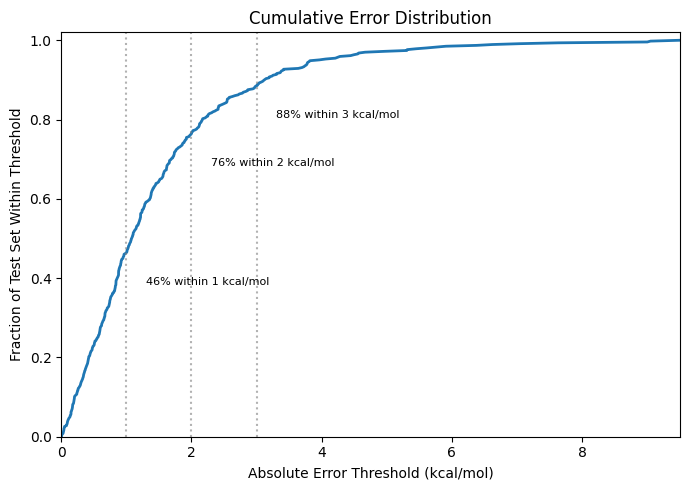

In [178]:


sorted_errors = np.sort(predictions["abs_error"])
cumulative_frac = np.arange(1, len(sorted_errors) + 1) / len(sorted_errors)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(sorted_errors, cumulative_frac, linewidth=2)
for threshold in [1, 2, 3]:
    frac_within = (predictions["abs_error"] <= threshold).mean()
    ax.axvline(threshold, color="gray", linestyle=":", alpha=0.6)
    ax.annotate(f"{frac_within:.0%} within {threshold} kcal/mol", xy=(threshold, frac_within),
                xytext=(threshold + 0.3, frac_within - 0.08), fontsize=8)
ax.set_xlabel("Absolute Error Threshold (kcal/mol)")
ax.set_ylabel("Fraction of Test Set Within Threshold")
ax.set_title("Cumulative Error Distribution")
ax.set_xlim(0, sorted_errors.max())
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig("plots_dHfus_cumulative_error.png", dpi=150)
plt.show()


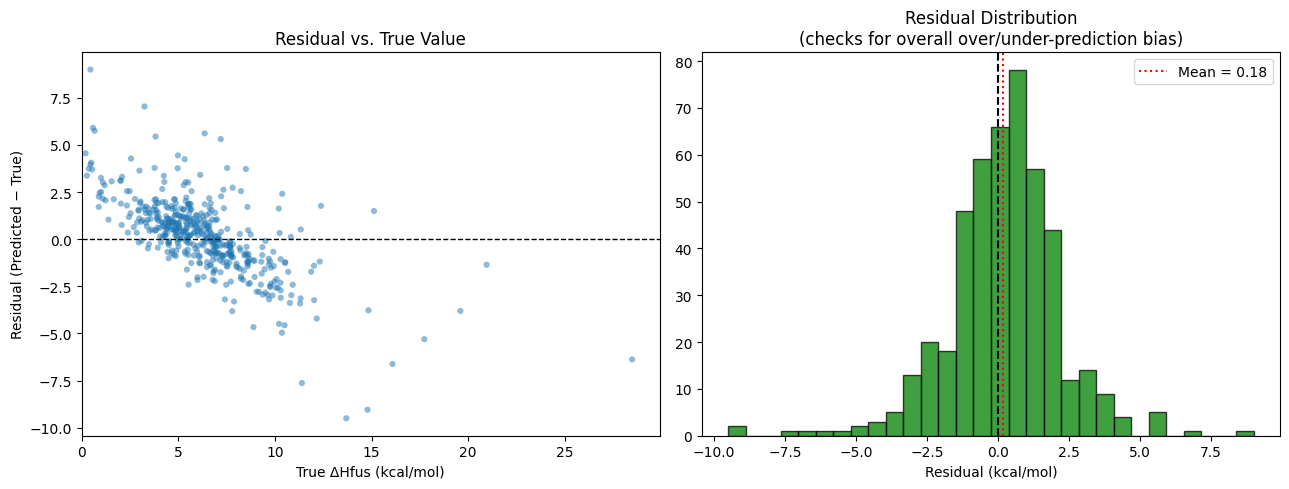

Correlation between true value and residual: -0.691 (strongly negative = regression-to-mean bias)
Mean residual: 0.184


In [179]:



predictions["residual"] = predictions["y_pred"] - predictions["y_true"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(predictions["y_true"], predictions["residual"], alpha=0.5, s=20, edgecolor="none")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_xlim(0, predictions["y_true"].max() * 1.05)
axes[0].set_xlabel("True ΔHfus (kcal/mol)")
axes[0].set_ylabel("Residual (Predicted − True)")
axes[0].set_title("Residual vs. True Value")

axes[1].hist(predictions["residual"], bins=30, edgecolor="black", alpha=0.75, color="green")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].axvline(predictions["residual"].mean(), color="red", linestyle=":", label=f"Mean = {predictions['residual'].mean():.2f}")
axes[1].set_xlabel("Residual (kcal/mol)")
axes[1].set_title("Residual Distribution\n(checks for overall over/under-prediction bias)")
axes[1].legend()

plt.tight_layout()
plt.savefig("plots_dHfus_residuals_full.png", dpi=150)
plt.show()

corr = np.corrcoef(predictions["y_true"], predictions["residual"])[0, 1]
print(f"Correlation between true value and residual: {corr:.3f} (strongly negative = regression-to-mean bias)")
print(f"Mean residual: {predictions['residual'].mean():.3f}")